In [31]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [32]:
keep = ["story_id", "correct_letter", "predicted_letter", "true_genre"]
df = pd.read_parquet("data/w2-d2_genre-attributions.parquet", columns=keep)
df.shape

(500, 4)

In [33]:
# load layerwise hidden states
array_cache = np.load("data/w2-d3_genre-hidden-states.npz")

In [34]:
hidden_states = array_cache["hidden_states"]
story_ids = array_cache["story_ids"]

In [35]:
df = df.set_index("story_id").loc[story_ids].reset_index()

In [36]:
print("Hidden states for a story:", hidden_states[0].shape)

Hidden states for a story: (33, 4096)


In [37]:
# Shape: num_doc, num_layer, dim
# - dim is NOT vocabulary size
# - We still had to make a decison about which vector to choose, given then fact
# that all tokens in input have a 4096-dim vector for every layer. So which
# did we select? We selected the last token in the input
# - What we don't have in this information is a genre lable.


hidden_states.shape

(500, 33, 4096)

In [38]:
df = df.set_index("story_id").loc[story_ids].reset_index()

In [42]:
# remember: how did we hidden states?
#
# Day 3
# with torch.no_grad()
#     outputs = model(**inputs, output_hidden_states=True)
#     outputs.hidden_states -> a tuple of num_layer hidden states for every token in the input.


In [43]:
4096 * 33 # this completely ignores the fact that every output is in its vector space, and the output
          # of a Transformer is the result of a non-linear transformer. Chris Potts's group "onion paper"

135168

In [44]:
# A linear space assumes that if you take a step forward, you can take that same step, and return
# back to where you were
# A non-linear spaces (manifold) says no you fucking can't (yeh)
#
# An open, but testable question whether each hiddne state vector space is linear or nonlinear
# It's probably never the case that a nonlinear activation function, which is the result of a
# Transformer block, means that you can join two vector spaces and expect them to have the 
# same properties

In [45]:
# we're gonna build linear probes, which will attempt to recover genre from hidden dims at each layer.
def probe_layer(X, y, n_splits=5, seed=5167):
    """Train a cross-validated logistic regression probe a layer.

    Parameters
    ----------
    X : np.ndarray
        Hidden states for the layer, shape （n_story, d_model）
    y: np.ndarray
        Target lables, shape (n_story,)

    Returns
    -------
    float
        Mean accuracy over the folds (where folds are individual models trained on
        test/eval splits of X)
    """
    pipe = make_pipeline(
        StandardScaler(), # Removing the mean and centering on 0
        LogisticRegression (C=1, max_iter=2000),
    )
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    scores = cross_val_score(pipe, X, y, cv=cv, scoring="accuracy", n_jobs=-1)

    return scores.mean()

In [46]:
# Let's train probs:
# 1. Genre: Can a probe predict the correct genre from hidden states?
# 2. Correct letter: Can a probe predict which answer letter represents that genre?
# 3. Predicted Letter: can a probe predict which letter Olmo 3 ultimately chose (whether correct or not)?
#
# When we fit a probe at a leyr, ecah of the following will serve as 'y'
genre = df["true_genre"].to_numpy()
correct_letter = df["correct_letter"].to_numpy()
predicted_letter = df["predicted_letter"].to_numpy()

In [47]:
rng = np.random.default_rng(5167)
shuffled_letter = rng.permutation(correct_letter)

In [48]:
n_layer = hidden_states.shape[1]

n_layer = hidden_states.shape[1]

all_results = []
for layer in range(n_layer):
    X = hidden_states[:, layer, :].astype(np.float64)
    results = {
        "layer": layer,
        "genre": probe_layer(X, genre),
        "correct_letter": probe_layer(X, correct_letter),
        "predicted_letter": probe_layer(X, predicted_letter),
        "shuffled": probe_layer(X, shuffled_letter),
    }

    all_results.append(results)

probe_df = pd.DataFrame(all_results)

In [49]:
probe_df = pd.DataFrame(all_results)
probe_plot = probe_df.melt(
    id_vars="layer",
    value_vars=["genre", "correct_letter", "predicted_letter", "shuffled"],
    var_name="Probe target",
    value_name="accuracy",
)
probe_plot.groupby("Probe target")["accuracy"].describe()

,count,mean,std,min,25%,50%,75%,max
Probe target,,,,,,,,
correct_letter,33.0,0.352727,0.117041,0.188,0.238,0.386,0.466,0.504
genre,33.0,0.888485,0.049427,0.718,0.866,0.890,0.918,0.956
predicted_letter,33.0,0.476182,0.145528,0.262,0.332,0.466,0.620,0.708
shuffled,33.0,0.205152,0.013500,0.168,0.196,0.208,0.214,0.230


In [52]:
FACET_HEIGHT = 4
FACET_ASPECT = 1.2

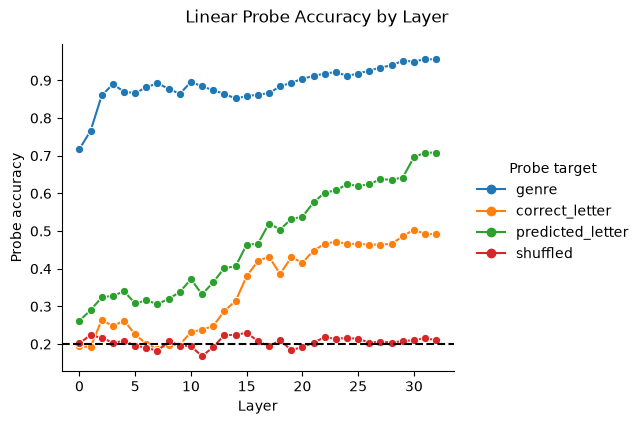

In [53]:
g = sns.relplot(
    data=probe_plot,
    kind="line",
    x="layer",
    y="accuracy",
    hue="Probe target",
    marker="o",
    height=FACET_HEIGHT,
    aspect=FACET_ASPECT,
)
g.refline(y=1/5, color="black", linestyle="--")
g.set_axis_labels("Layer", "Probe accuracy")
g.fig.suptitle("Linear Probe Accuracy by Layer", y=1.05)
plt.show()

In [54]:
clf_cache = np.load("data/w2-d3_linear-classifier.npz")

In [55]:
layer = clf_cache["chosen_layer"].item()
print("Selected Transformer block:", layer)

acc = clf_cache["held_out_accuracy"].item()
print("Held-out accuracy:", round(acc, 3))


Selected Transformer block: 27
Held-out accuracy: 0.973


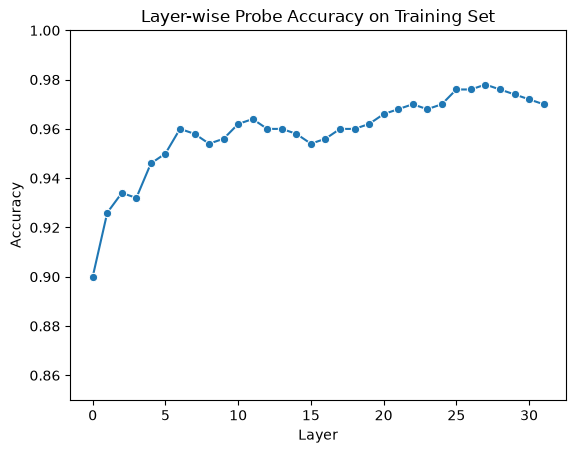

In [56]:
cv_acc = clf_cache["cv_accuracy_by_layer"]

fig, ax = plt.subplots()
sns.lineplot(x=range(len(cv_acc)), y=cv_acc, marker="o", ax=ax)
ax.set(
    title="Layer-wise Probe Accuracy on Training Set",
    xlabel="Layer",
    ylabel="Accuracy",
    ylim=(0.85, 1.0),
)
plt.show()

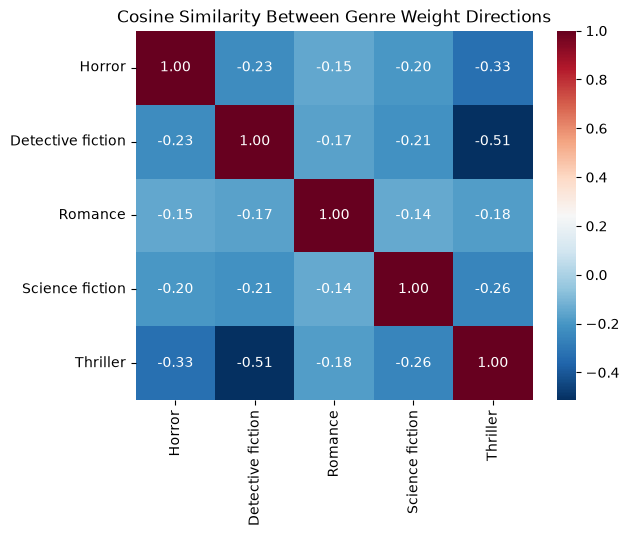

In [57]:
W = clf_cache["head_weight"]
Wn = W / np.linalg.norm(W, axis=1, keepdims=True)
cos_sim = Wn @ Wn.T

genres = clf_cache["genre_classes"].astype(str)
cos_sim = pd.DataFrame(cos_sim, index=genres, columns=genres)

fig, ax = plt.subplots()
sns.heatmap(cos_sim, cmap="RdBu_r", annot=True, fmt=".2f", ax=ax)
ax.set(title="Cosine Similarity Between Genre Weight Directions")
plt.show()

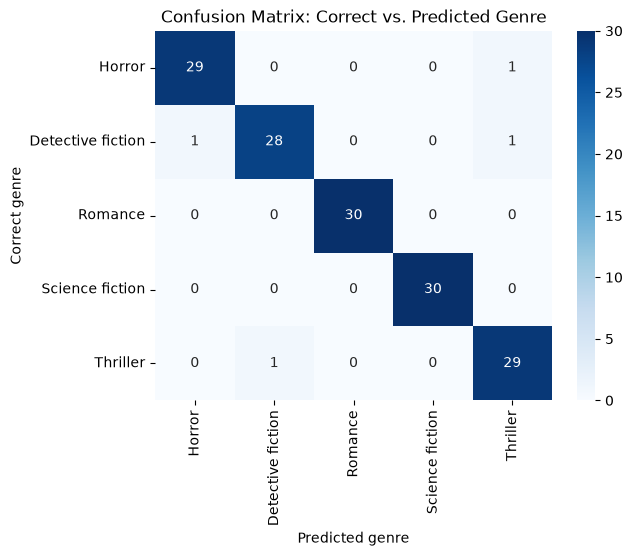

In [58]:
b = clf_cache["head_bias"]
head_pooled_states = clf_cache["pooled_states"]

X_layer = head_pooled_states[:, layer, :] 
test_idx = clf_cache["test_idx"]

GENRES = np.array([
    "Horror",
    "Detective fiction",
    "Romance",
    "Science fiction",
    "Thriller",
])

test_logits = X_layer[test_idx] @ W.T + b
y_pred = GENRES[test_logits.argmax(axis=1)]

y_true = df.loc[test_idx, "true_genre"]

confusion_matrix = (
    pd.crosstab(y_true, y_pred).reindex(columns=GENRES, index=GENRES)
)

fig, ax = plt.subplots()
sns.heatmap(confusion_matrix, cmap="Blues", annot=True, fmt="d", ax=ax)
ax.set(
    title="Confusion Matrix: Correct vs. Predicted Genre",
    xlabel="Predicted genre",
    ylabel="Correct genre",
)
plt.show()


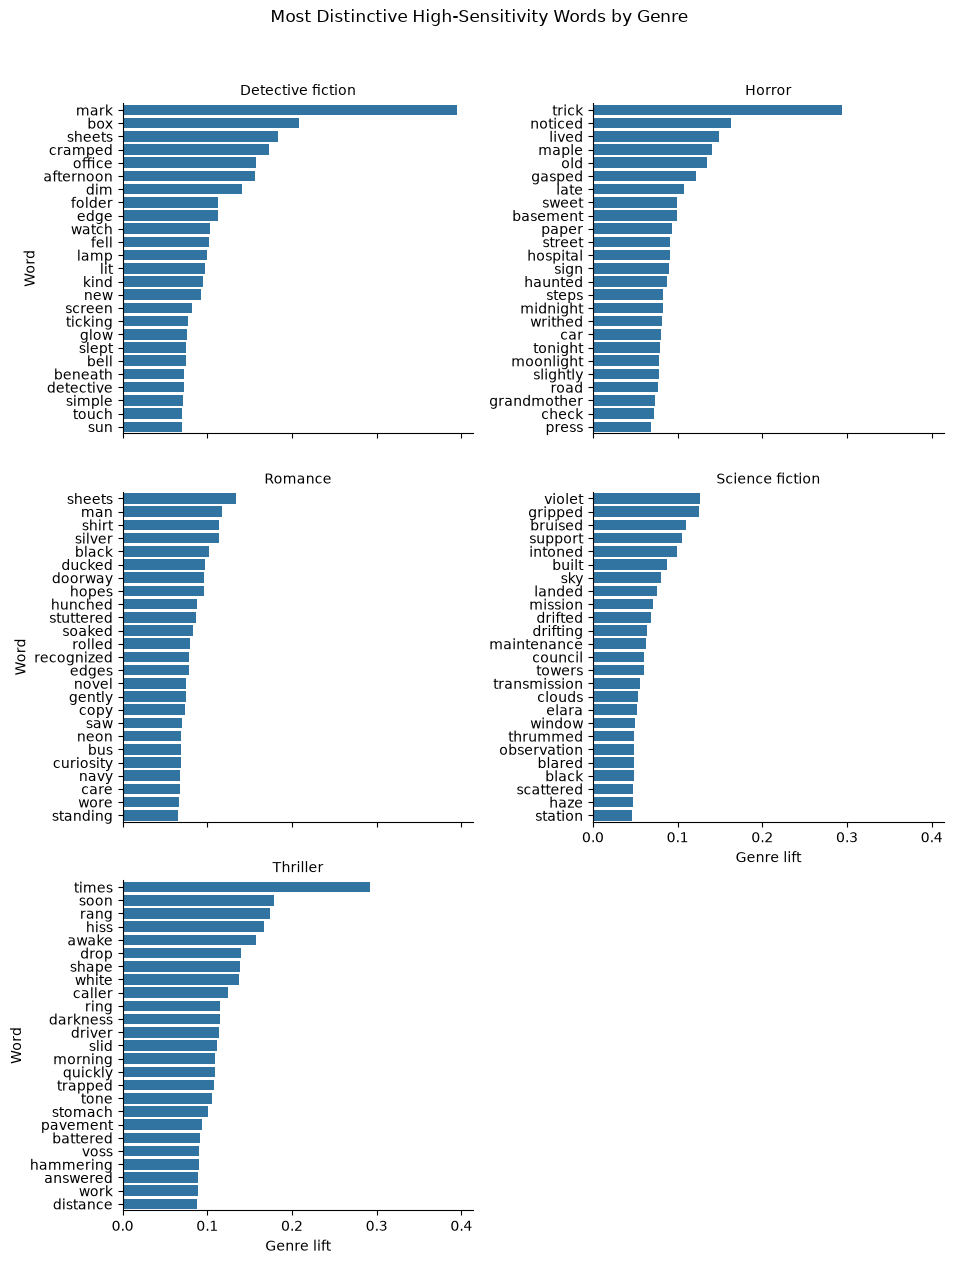

In [64]:
clf_lift = pd.read_parquet("data/w2-d3_classifier-genre-lift.parquet")

genre_counts = clf_lift.groupby("genre").size().to_frame(name="count")
genre_counts

k = 25
most_distinctive = (
    clf_lift
    .sort_values(["genre", "genre_lift"], ascending=[True, False])
    .groupby("genre", as_index=False)
    .head(k)[["genre", "word", "genre_lift"]]
    .reset_index(drop=True)
)

g = sns.catplot(
    data=most_distinctive,
    kind="bar",
    x="genre_lift",
    y="word",
    col="genre",
    col_wrap=2,
    sharey=False,
    height=FACET_HEIGHT,
    aspect=FACET_ASPECT,
)
g.set_axis_labels("Genre lift", "Word")
g.set_titles("{col_name}")
g.fig.suptitle("Most Distinctive High-Sensitivity Words by Genre", y=1.05)
plt.show()

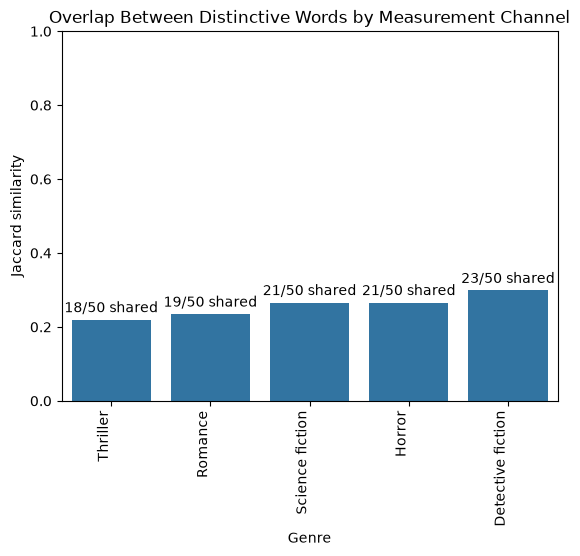

Mean Jaccard similarity: 0.257
Mean shared words: 20.4 out of 50
Mean shared-word share: 0.408


In [65]:
mcqa_lift = pd.read_parquet("data/w2-d3_mcqa-genre-lift.parquet")

def jaccard(a, b):
    """Compute Jaccard similarity between two word lists.

    Parameters
    ----------
    a : set[str]
        Set of words
    b : ste[str]
        Set of words

    Returns
    -------
    float
        Jaccard similarity
    """
    union = a | b
    if len(union) == 0:
        return 0.0

    return len(a & b) / len(union)






k = 50
overlap = []

for genre in GENRES:
    m_words = (
        mcqa_lift[mcqa_lift["genre"] == genre]
        .sort_values("genre_lift", ascending=False)
        .head(k)
    )
    c_words = (
        clf_lift[clf_lift["genre"] == genre]
        .sort_values("genre_lift", ascending=False)
        .head(k)
    )

    m_words = set(m_words["word"])
    c_words = set(c_words["word"])
    
    shared = len(m_words & c_words)
    score = jaccard(m_words, c_words)

    overlap.append(
        {
            "genre": genre,
            "jaccard": score,
            "shared": len(m_words & c_words),
            "shared_share": shared / k,
        }
    )

overlap_df = pd.DataFrame(overlap)
overlap_df = overlap_df.sort_values("jaccard")



fig, ax = plt.subplots()
sns.barplot(overlap_df, x="genre", y="jaccard", ax=ax)
ax.set(
    title="Overlap Between Distinctive Words by Measurement Channel",
    xlabel="Genre",
    ylabel="Jaccard similarity",
    ylim=(0, 1),
)

for container in ax.containers:
    labels = []
    for shared in overlap_df["shared"]:
        label = f"{shared}/{k} shared"
        labels.append(label)

    ax.bar_label(
        container, labels=labels, padding=3
    )

plt.xticks(rotation=90, ha="right")
plt.show()




mean_jaccard = overlap_df["jaccard"].mean()
mean_shared = overlap_df["shared"].mean()
mean_shared_share = overlap_df["shared_share"].mean()

print("Mean Jaccard similarity:", round(mean_jaccard, 3))
print("Mean shared words:", round(mean_shared, 1), "out of", k)
print("Mean shared-word share:", round(mean_shared_share, 3))






In [67]:
mcqa_lift = pd.read_parquet("data/w2-d3_mcqa-genre-lift.parquet")

mcqa_lift[mcqa_lift["genre"] == "science fiction"].nlargest(25, "genre_lift")


,genre,word,grad_mean_across_stories,grad_sum_across_stories,n_stories,n_occurrences,global_grad_mean,genre_lift
